In [1]:
import numpy as np 
import pandas as pd 
import matplotlib.pyplot as plt

from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

In [3]:
train_data = pd.read_csv("optdigits.tra", header=None)
test_data = pd.read_csv("optdigits.tes", header=None)

print("Train data shape:", train_data.shape)
print("Test data shape:", test_data.shape)

Train data shape: (3823, 65)
Test data shape: (1797, 65)


In [10]:
display(train_data.head())
display(test_data.head())
print(train_data.info())

,0,1,2,3,4,5,6,7,8,9,...,55,56,57,58,59,60,61,62,63,64
0,0,1,6,15,12,1,0,0,0,7,...,0,0,0,6,14,7,1,0,0,0
1,0,0,10,16,6,0,0,0,0,7,...,0,0,0,10,16,15,3,0,0,0
2,0,0,8,15,16,13,0,0,0,1,...,0,0,0,9,14,0,0,0,0,7
3,0,0,0,3,11,16,0,0,0,0,...,0,0,0,0,1,15,2,0,0,4
4,0,0,5,14,4,0,0,0,0,0,...,0,0,0,4,12,14,7,0,0,6


,0,1,2,3,4,5,6,7,8,9,...,55,56,57,58,59,60,61,62,63,64
0,0,0,5,13,9,1,0,0,0,0,...,0,0,0,6,13,10,0,0,0,0
1,0,0,0,12,13,5,0,0,0,0,...,0,0,0,0,11,16,10,0,0,1
2,0,0,0,4,15,12,0,0,0,0,...,0,0,0,0,3,11,16,9,0,2
3,0,0,7,15,13,1,0,0,0,8,...,0,0,0,7,13,13,9,0,0,3
4,0,0,0,1,11,0,0,0,0,0,...,0,0,0,0,2,16,4,0,0,4


<class 'pandas.DataFrame'>
RangeIndex: 3823 entries, 0 to 3822
Data columns (total 65 columns):
 #   Column  Non-Null Count  Dtype
---  ------  --------------  -----
 0   0       3823 non-null   int64
 1   1       3823 non-null   int64
 2   2       3823 non-null   int64
 3   3       3823 non-null   int64
 4   4       3823 non-null   int64
 5   5       3823 non-null   int64
 6   6       3823 non-null   int64
 7   7       3823 non-null   int64
 8   8       3823 non-null   int64
 9   9       3823 non-null   int64
 10  10      3823 non-null   int64
 11  11      3823 non-null   int64
 12  12      3823 non-null   int64
 13  13      3823 non-null   int64
 14  14      3823 non-null   int64
 15  15      3823 non-null   int64
 16  16      3823 non-null   int64
 17  17      3823 non-null   int64
 18  18      3823 non-null   int64
 19  19      3823 non-null   int64
 20  20      3823 non-null   int64
 21  21      3823 non-null   int64
 22  22      3823 non-null   int64
 23  23      3823 non-null   

In [9]:
train_data.describe()
print("Missing values in training data")
print(train_data.isnull().sum().sum())

print("missing values in test data")
print(test_data.isnull().sum().sum())

Missing values in training data
0
missing values in test data
0


In [14]:
print("duplicates in train",
train_data.duplicated().sum())

print("duplicates in test",
    test_data.duplicated().sum())

duplicates in train 0
duplicates in test 0


In [15]:
print("Training target values:")
print(train_data[64].value_counts().sort_index())

print("\nTesting target values:")
print(test_data[64].value_counts().sort_index())

Training target values:
64
0    376
1    389
2    380
3    389
4    387
5    376
6    377
7    387
8    380
9    382
Name: count, dtype: int64

Testing target values:
64
0    178
1    182
2    177
3    183
4    181
5    182
6    181
7    179
8    174
9    180
Name: count, dtype: int64


Text(0.5, 1.0, 'Training data digit distribution')

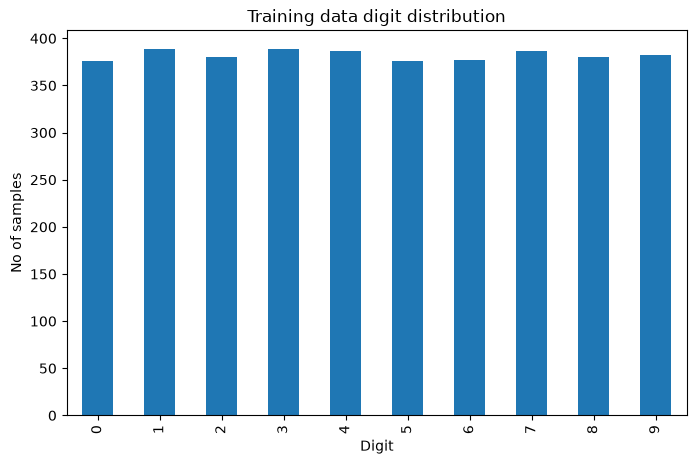

In [29]:
plt.figure(figsize = (8,5))

train_data[64].value_counts().sort_index().plot(kind="bar")

plt.xlabel("Digit")
plt.ylabel("No of samples")
plt.title("Training data digit distribution")


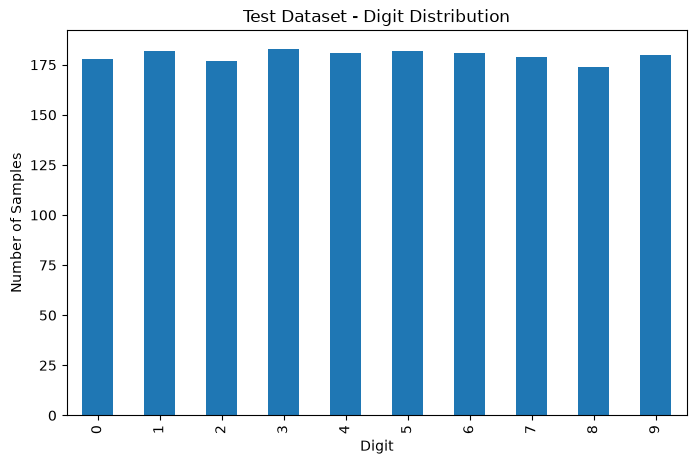

In [30]:
plt.figure(figsize=(8, 5))

test_data[64].value_counts().sort_index().plot(
    kind="bar"
)

plt.xlabel("Digit")
plt.ylabel("Number of Samples")
plt.title("Test Dataset - Digit Distribution")

plt.show()

In [19]:
#examine pixel value distribution
pixel_train = train_data.iloc[:, :-1]
pixel_test = test_data.iloc[:, :-1]

print("Training pixel statistics", pixel_train.describe())
print("Testing pixel statistics", pixel_test.describe())

Training pixel statistics            0            1            2            3            4   \
count  3823.0  3823.000000  3823.000000  3823.000000  3823.000000   
mean      0.0     0.301334     5.481821    11.805912    11.451478   
std       0.0     0.866986     4.631601     4.259811     4.537556   
min       0.0     0.000000     0.000000     0.000000     0.000000   
25%       0.0     0.000000     1.000000    10.000000     9.000000   
50%       0.0     0.000000     5.000000    13.000000    13.000000   
75%       0.0     0.000000     9.000000    15.000000    15.000000   
max       0.0     8.000000    16.000000    16.000000    16.000000   

                5            6            7            8            9   ...  \
count  3823.000000  3823.000000  3823.000000  3823.000000  3823.000000  ...   
mean      5.505362     1.387392     0.142297     0.002093     1.960502  ...   
std       5.613060     3.371444     1.051598     0.088572     3.052353  ...   
min       0.000000     0.000000     

In [20]:
#checking pixel value range
print("Training pixel minimum:", pixel_train.min().min())
print("Training pixel maximum:", pixel_train.max().max())

print("\nTesting pixel minimum:", pixel_test.min().min())
print("Testing pixel maximum:", pixel_test.max().max())

Training pixel minimum: 0
Training pixel maximum: 16

Testing pixel minimum: 0
Testing pixel maximum: 16


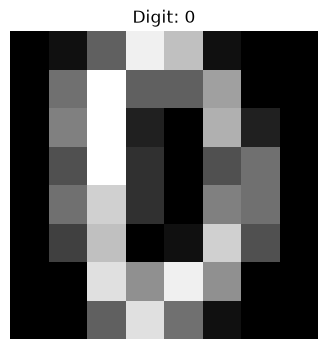

In [ ]:
#visualize one digit

image = pixel_train.iloc[0].values.reshape(8,8)
plt.figure(figsize = (4,4))
plt.imshow(image, cmap="gray")
plt.title(f"Digit: {train_data.iloc[0, -1]}")
plt.axis("off")
plt.show()

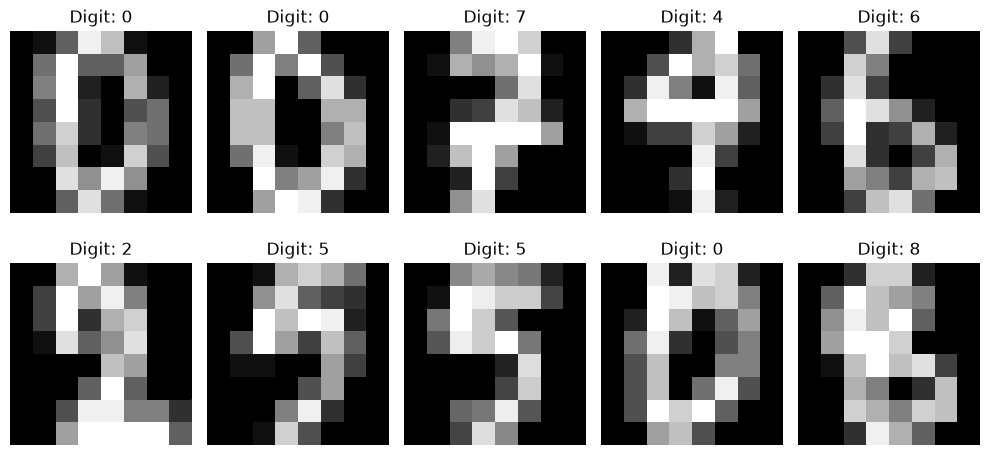

In [24]:
#visualize several digits
fig, axes = plt.subplots(2,5, figsize=(10,5))
for i, ax in enumerate(axes.flat):
    image = pixel_train.iloc[i].values.reshape(8,8)

    ax.imshow(image, cmap="gray")
    ax.set_title(f"Digit: {train_data.iloc[i, -1]}")
    ax.axis("off")

plt.tight_layout()
plt.show()

In [25]:
mean_pixels = pixel_train.mean()

print(mean_pixels)

0      0.000000
1      0.301334
2      5.481821
3     11.805912
4     11.451478
        ...    
59    11.942977
60    11.461156
61     6.700497
62     2.105676
63     0.202197
Length: 64, dtype: float64


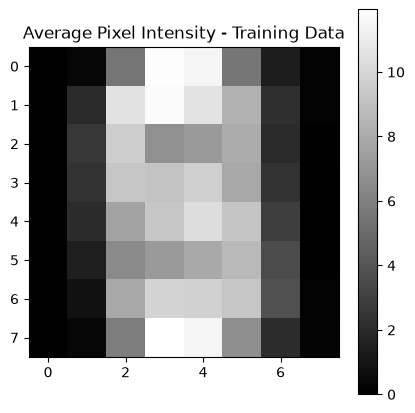

In [26]:
mean_image = mean_pixels.values.reshape(8, 8)

plt.figure(figsize=(5, 5))

plt.imshow(mean_image, cmap="gray")

plt.title("Average Pixel Intensity - Training Data")
plt.colorbar()

plt.show()

0      0.000000
1      0.751665
2     21.451723
3     18.145993
4     20.589416
        ...    
59    18.787956
60    24.919409
61    33.360039
62    16.226925
63     1.324098
Length: 64, dtype: float64


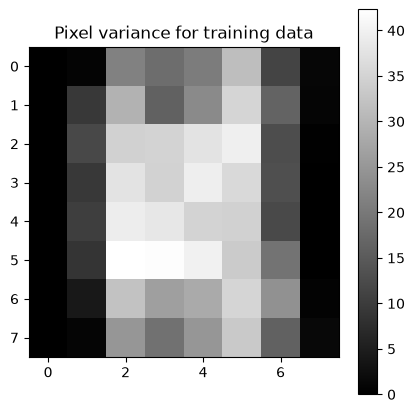

In [27]:
pixel_variance = pixel_train.var()
print(pixel_variance)

variance_image = pixel_variance.values.reshape(8,8)
plt.figure(figsize = (5,5))
plt.imshow(variance_image, cmap="gray")
plt.title("Pixel variance for training data")
plt.colorbar()
plt.show()

In [28]:
print("Training pixel shape:", pixel_train.shape)
print("Testing pixel shape:", pixel_test.shape)

print("\nTraining pixel mean:")
print(pixel_train.mean().mean())

print("\nTesting pixel mean:")
print(pixel_test.mean().mean())

print("\nTraining pixel standard deviation:")
print(pixel_train.stack().std())

print("\nTesting pixel standard deviation:")
print(pixel_test.stack().std())

Training pixel shape: (3823, 64)
Testing pixel shape: (1797, 64)

Training pixel mean:
4.923971684540937

Testing pixel mean:
4.884164579855314

Training pixel standard deviation:
6.03649792151461

Testing pixel standard deviation:
6.016813706968991


In [31]:
X_train = train_data.iloc[:, :-1]
y_train = train_data.iloc[:, -1]

X_test = test_data.iloc[:, :-1]
y_test = test_data.iloc[:, -1]

print("X_train:", X_train.shape)
print("y_train:", y_train.shape)

print("X_test:", X_test.shape)
print("y_test:", y_test.shape)

X_train: (3823, 64)
y_train: (3823,)
X_test: (1797, 64)
y_test: (1797,)


In [32]:
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("Scaled training shape:", X_train_scaled.shape)
print("Scaled testing shape:", X_test_scaled.shape)

Scaled training shape: (3823, 64)
Scaled testing shape: (1797, 64)


In [33]:
print("Mean of first 5 scaled features:")
print(X_train_scaled[:, :5].mean(axis=0))

print("\nStandard deviation of first 5 scaled features:")
print(X_train_scaled[:, :5].std(axis=0))

Mean of first 5 scaled features:
[ 0.00000000e+00  4.27477973e-17 -4.83235970e-17  1.87718588e-16
  1.20808992e-16]

Standard deviation of first 5 scaled features:
[0. 1. 1. 1. 1.]


In [34]:
pca = PCA()

X_train_pca = pca.fit_transform(X_train_scaled)

print("Original dimensions:", X_train_scaled.shape[1])
print("PCA dimensions:", X_train_pca.shape[1])

Original dimensions: 64
PCA dimensions: 64


In [35]:
explained_variance = pca.explained_variance_ratio_

print(explained_variance)

[1.16390519e-01 1.05157939e-01 7.62637875e-02 5.71196171e-02
 4.96873006e-02 4.64810382e-02 3.85458353e-02 3.37905063e-02
 2.85103132e-02 2.63091579e-02 2.50359564e-02 2.40869073e-02
 2.27882687e-02 2.09357664e-02 1.95580591e-02 1.89091193e-02
 1.84338560e-02 1.80092864e-02 1.62215674e-02 1.56513412e-02
 1.42523410e-02 1.37833414e-02 1.28868420e-02 1.12881932e-02
 1.06152420e-02 1.01262128e-02 9.72703327e-03 9.29472138e-03
 8.63324788e-03 8.24354471e-03 7.87725165e-03 7.12658067e-03
 6.95497230e-03 6.29398177e-03 6.07751848e-03 5.92961085e-03
 5.33856788e-03 4.88499246e-03 4.51338338e-03 4.46157597e-03
 4.35509690e-03 4.01866465e-03 3.85701372e-03 3.45350213e-03
 3.32455556e-03 3.09778534e-03 3.07226655e-03 2.77881179e-03
 2.66685310e-03 2.56958541e-03 2.42814868e-03 2.35894807e-03
 2.18329701e-03 2.07731606e-03 1.92919098e-03 1.80669826e-03
 1.63250282e-03 1.53692560e-03 1.42054743e-03 1.23765977e-03
 1.06561754e-03 9.33715516e-04 1.00608455e-18 0.00000000e+00]


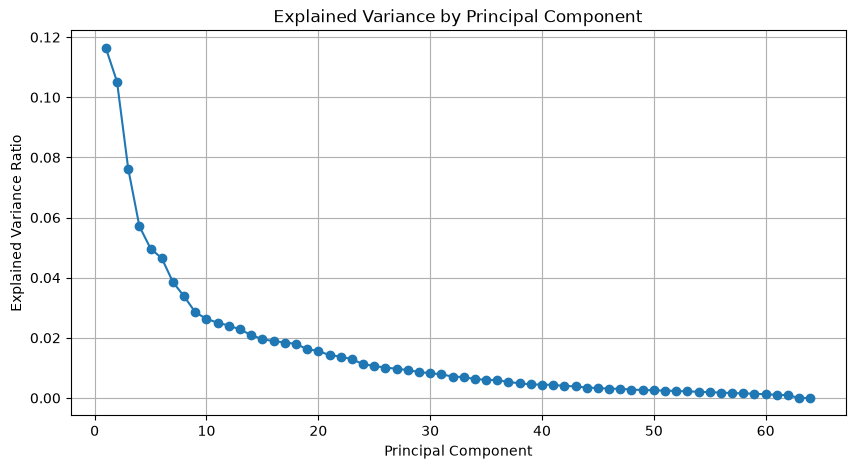

In [36]:
plt.figure(figsize=(10, 5))

plt.plot(
    range(1, len(explained_variance) + 1),
    explained_variance,
    marker="o"
)

plt.xlabel("Principal Component")
plt.ylabel("Explained Variance Ratio")
plt.title("Explained Variance by Principal Component")

plt.grid()
plt.show()

In [37]:
cumulative_variance = np.cumsum(explained_variance)

print(cumulative_variance)

[0.11639052 0.22154846 0.29781225 0.35493186 0.40461916 0.4511002
 0.48964604 0.52343654 0.55194686 0.57825601 0.60329197 0.62737888
 0.65016715 0.67110291 0.69066097 0.70957009 0.72800395 0.74601323
 0.7622348  0.77788614 0.79213848 0.80592182 0.81880867 0.83009686
 0.8407121  0.85083831 0.86056535 0.86986007 0.87849332 0.88673686
 0.89461411 0.90174069 0.90869567 0.91498965 0.92106717 0.92699678
 0.93233535 0.93722034 0.94173372 0.9461953  0.95055039 0.95456906
 0.95842607 0.96187957 0.96520413 0.96830192 0.97137418 0.97415299
 0.97681985 0.97938943 0.98181758 0.98417653 0.98635983 0.98843714
 0.99036633 0.99217303 0.99380553 0.99534246 0.99676301 0.99800067
 0.99906628 1.         1.         1.        ]


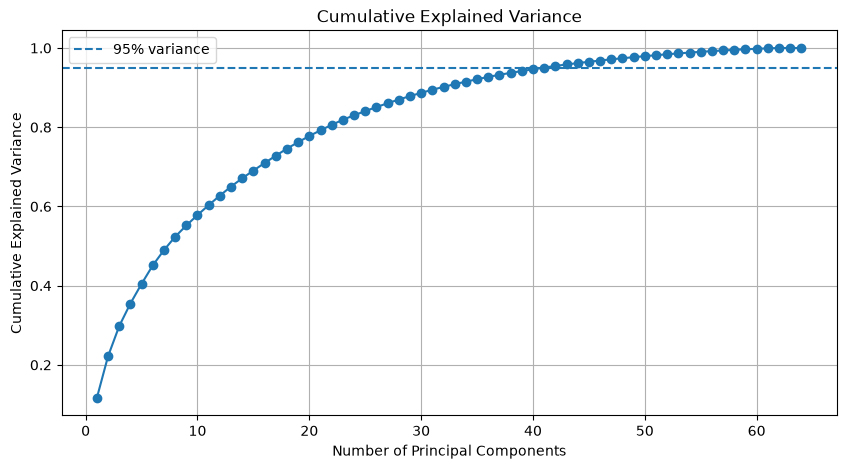

In [38]:
plt.figure(figsize=(10, 5))

plt.plot(
    range(1, len(cumulative_variance) + 1),
    cumulative_variance,
    marker="o"
)

plt.axhline(
    y=0.95,
    linestyle="--",
    label="95% variance"
)

plt.xlabel("Number of Principal Components")
plt.ylabel("Cumulative Explained Variance")
plt.title("Cumulative Explained Variance")

plt.legend()
plt.grid()

plt.show()

In [39]:
n_components_95 = np.argmax(
    cumulative_variance >= 0.95
) + 1

print(
    "Number of components needed for 95% variance:",
    n_components_95
)

Number of components needed for 95% variance: 41


In [40]:
pca_final = PCA(
    n_components=n_components_95
)

X_train_reduced = pca_final.fit_transform(
    X_train_scaled
)

X_test_reduced = pca_final.transform(
    X_test_scaled
)

print("Original training dimensions:", X_train_scaled.shape)
print("Reduced training dimensions:", X_train_reduced.shape)

print("\nOriginal testing dimensions:", X_test_scaled.shape)
print("Reduced testing dimensions:", X_test_reduced.shape)

Original training dimensions: (3823, 64)
Reduced training dimensions: (3823, 41)

Original testing dimensions: (1797, 64)
Reduced testing dimensions: (1797, 41)


In [41]:
retained_variance = (
    pca_final.explained_variance_ratio_.sum()
)

print(
    "Total variance retained:",
    retained_variance
)

print(
    "Percentage of variance retained:",
    retained_variance * 100
)

Total variance retained: 0.9505503940244968
Percentage of variance retained: 95.05503940244968


In [42]:
pca_2d = PCA(n_components=2)

X_train_2d = pca_2d.fit_transform(X_train_scaled)

print("2D PCA shape:", X_train_2d.shape)

2D PCA shape: (3823, 2)


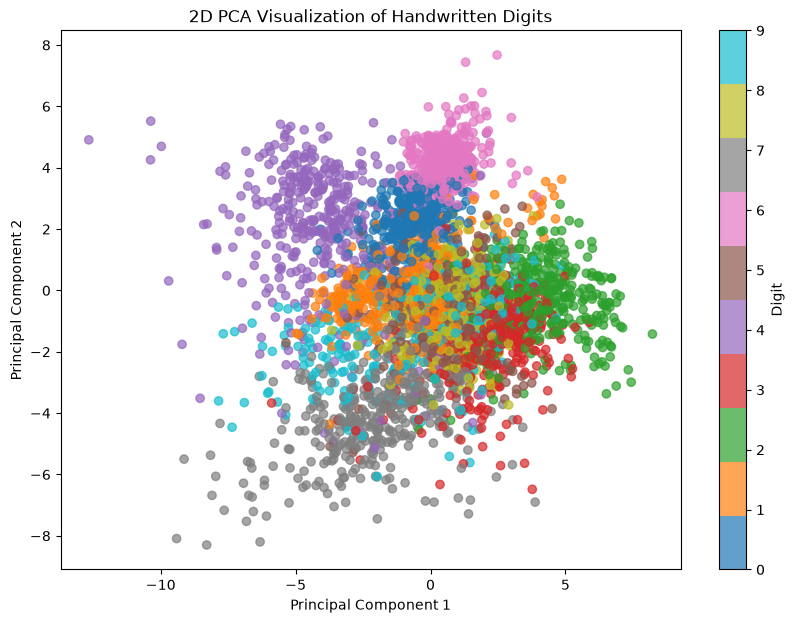

In [43]:
plt.figure(figsize=(10, 7))

scatter = plt.scatter(
    X_train_2d[:, 0],
    X_train_2d[:, 1],
    c=y_train,
    cmap="tab10",
    alpha=0.7
)

plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.title("2D PCA Visualization of Handwritten Digits")

plt.colorbar(
    scatter,
    label="Digit"
)

plt.show()

In [44]:
print("===== DIMENSION COMPARISON =====")

print("Original training data:")
print("Samples:", X_train.shape[0])
print("Features:", X_train.shape[1])

print("\nReduced training data:")
print("Samples:", X_train_reduced.shape[0])
print("Components:", X_train_reduced.shape[1])

print("\nDimension reduction:")
print(
    X_train.shape[1],
    "→",
    X_train_reduced.shape[1]
)

===== DIMENSION COMPARISON =====
Original training data:
Samples: 3823
Features: 64

Reduced training data:
Samples: 3823
Components: 41

Dimension reduction:
64 → 41


In [45]:
reduction_percentage = (
    1 - X_train_reduced.shape[1] / X_train.shape[1]
) * 100

print(
    "Dimensionality reduction:",
    reduction_percentage,
    "%"
)

Dimensionality reduction: 35.9375 %


In [46]:
print("Original test dimensions:", X_test.shape)

print(
    "Reduced test dimensions:",
    X_test_reduced.shape
)

Original test dimensions: (1797, 64)
Reduced test dimensions: (1797, 41)
